##  Instalação do PySpark

Instala a biblioteca PySpark para permitir o processamento e a análise dos
dados.

In [ ]:
!pip install pyspark

##  Conexão com o Google Drive

Conecta o Google Colab ao Google Drive para acessar os arquivos do projeto.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


##  Importação das bibliotecas

Importa as bibliotecas necessárias para processamento, manipulação, análise e visualização dos dados.

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.sql.window import Window

## Inicialização do Spark

Cria a sessão do Spark para executar as operações de processamento e análise dos dados.

In [ ]:
spark = SparkSession.builder \
    .appName("Olist_Analise_Exploratoria") \
    .master("local[*]") \
    .getOrCreate()

print("Spark iniciado com sucesso!")
print("Versão:", spark.version)

Spark iniciado com sucesso!
Versão: 4.0.5


## Carregamento das bases de dados

Define o caminho dos arquivos CSV, carrega as nove tabelas no Spark e apresenta a quantidade de registros de cada uma.

In [ ]:
pasta_dados = "/content/drive/MyDrive/Projeto_Olist/dados"

arquivos = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv"
]

tabelas = {}

for arquivo in arquivos:

    caminho = os.path.join(pasta_dados, arquivo)

    nome_tabela = arquivo.replace(".csv", "")

    tabelas[nome_tabela] = (
        spark.read
        .option("header", "true")
        .option("multiLine", "true")
        .option("inferSchema", "false")
        .csv(caminho)
    )

    print(f"{nome_tabela}: {tabelas[nome_tabela].count()} registros")

print("\nTodos os arquivos foram carregados!")

olist_customers_dataset: 99441 registros
olist_geolocation_dataset: 1000163 registros
olist_order_items_dataset: 112650 registros
olist_order_payments_dataset: 103886 registros
olist_order_reviews_dataset: 99249 registros
olist_orders_dataset: 99441 registros
olist_products_dataset: 32951 registros
olist_sellers_dataset: 3095 registros
product_category_name_translation: 71 registros

Todos os arquivos foram carregados!


## Listagem das tabelas

Exibe os nomes de todas as tabelas carregadas no Spark para conferir a disponibilidade dos dados.

In [ ]:
print("Tabelas carregadas:")

for nome in tabelas.keys():
    print("-", nome)

Tabelas carregadas:
- olist_customers_dataset
- olist_geolocation_dataset
- olist_order_items_dataset
- olist_order_payments_dataset
- olist_order_reviews_dataset
- olist_orders_dataset
- olist_products_dataset
- olist_sellers_dataset
- product_category_name_translation


## Visualização inicial das tabelas

Exibe a estrutura das tabelas (schema) e suas cinco primeiras linhas para conferir as colunas e os dados carregados.

In [ ]:
# Exibir as 5 primeiras linhas e o schema de cada tabela

for nome_tabela, dataframe in tabelas.items():

    print("=" * 80)
    print(f"TABELA: {nome_tabela}")
    print("=" * 80)

    print("\nSCHEMA:")
    dataframe.printSchema()

    print("\nPRIMEIRAS 5 LINHAS:")
    dataframe.show(5, truncate=False)

    print("\n")

TABELA: olist_customers_dataset

SCHEMA:
root
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)


PRIMEIRAS 5 LINHAS:
+--------------------------------+--------------------------------+------------------------+---------------------+--------------+
|customer_id                     |customer_unique_id              |customer_zip_code_prefix|customer_city        |customer_state|
+--------------------------------+--------------------------------+------------------------+---------------------+--------------+
|06b8999e2fba1a1fbc88172c00ba8bc7|861eff4711a542e4b93843c6dd7febb0|14409                   |franca               |SP            |
|18955e83d337fd6b2def6b18a428ac77|290c77bc529b7ac935b93aa66c333dc3|09790                   |sao bernardo do campo|SP            |
|4e7b3e00288586ebd08712fdd0374a03|060e732b

## Distribuição dos pedidos por status

Agrupa os pedidos por situação, calcula a quantidade de registros em cada status e organiza os resultados em ordem decrescente.

In [ ]:
orders = tabelas["olist_orders_dataset"]

distribuicao_status = (
    orders
    .groupBy("order_status")
    .agg(
        F.count("*").alias("quantidade")
    )
    .orderBy(F.desc("quantidade"))
)

# Exibir tabela
display(distribuicao_status.toPandas())

,order_status,quantidade
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## Visualização da distribuição dos pedidos por status

Gera um gráfico de barras para comparar a quantidade de pedidos em cada situação.

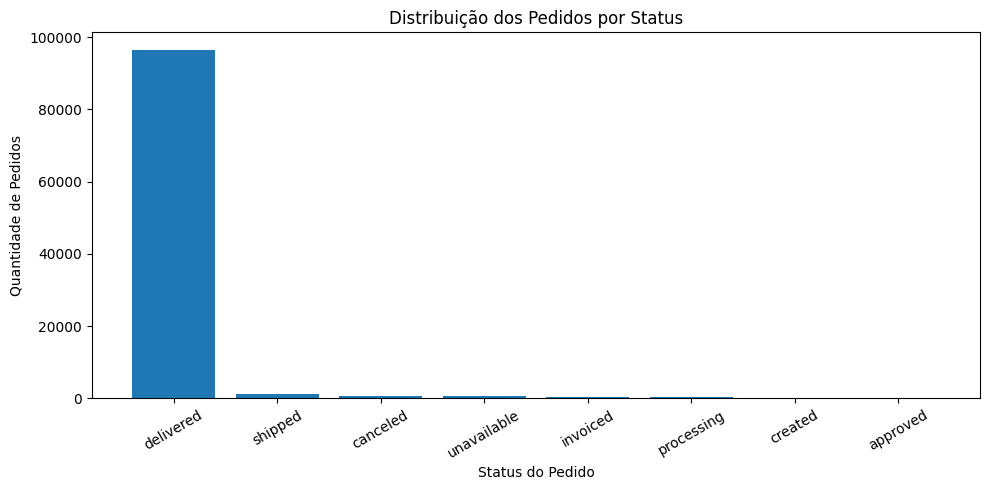

In [ ]:
dados_status = distribuicao_status.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    dados_status["order_status"],
    dados_status["quantidade"]
)

plt.title("Distribuição dos Pedidos por Status")
plt.xlabel("Status do Pedido")
plt.ylabel("Quantidade de Pedidos")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Distribuição de produtos por categoria

Agrupa os produtos por categoria, contabiliza os registros e identifica as 15 categorias com maior quantidade de produtos.

In [ ]:
products = tabelas["olist_products_dataset"]

distribuicao_categoria = (
    products
    .groupBy("product_category_name")
    .agg(
        F.count("*").alias("quantidade")
    )
    .orderBy(F.desc("quantidade"))
)

# Exibir as 15 categorias com mais produtos
top_categorias = distribuicao_categoria.limit(15)

display(top_categorias.toPandas())

,product_category_name,quantidade
0,cama_mesa_banho,3029
1,esporte_lazer,2867
2,moveis_decoracao,2657
3,beleza_saude,2444
4,utilidades_domesticas,2335
5,automotivo,1900
6,informatica_acessorios,1639
7,brinquedos,1411
8,relogios_presentes,1329
9,telefonia,1134


## Visualização das categorias com mais produtos

Gera um gráfico de barras horizontais para comparar as 15 categorias com maior quantidade de produtos cadastrados.

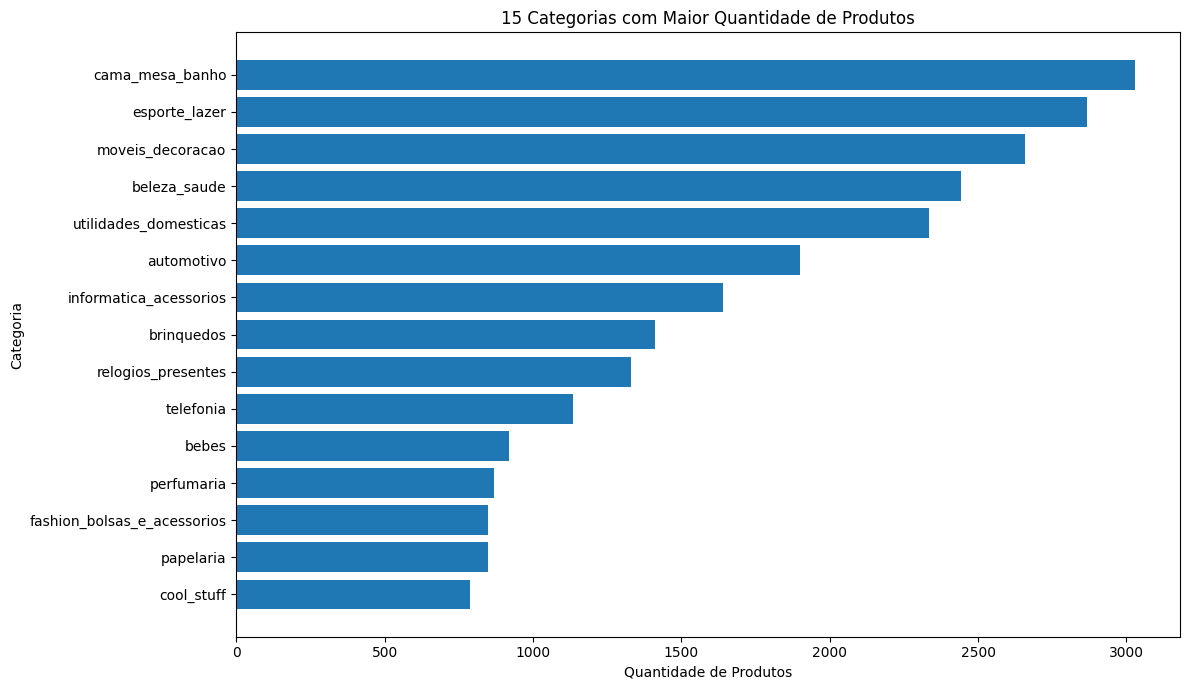

In [ ]:
dados_categoria = top_categorias.toPandas()

plt.figure(figsize=(12, 7))

plt.barh(
    dados_categoria["product_category_name"],
    dados_categoria["quantidade"]
)

plt.title("15 Categorias com Maior Quantidade de Produtos")
plt.xlabel("Quantidade de Produtos")
plt.ylabel("Categoria")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Evolução mensal dos pedidos

Converte a data da compra, agrupa os pedidos por ano e mês e calcula a quantidade de pedidos em cada período.

In [ ]:
orders = tabelas["olist_orders_dataset"]

pedidos_temporais = (
    orders
    .withColumn(
        "data_compra",
        F.to_timestamp("order_purchase_timestamp")
    )
    .withColumn(
        "ano_mes",
        F.date_format("data_compra", "yyyy-MM")
    )
    .filter(F.col("data_compra").isNotNull())
    .groupBy("ano_mes")
    .agg(
        F.count("*").alias("quantidade_pedidos")
    )
    .orderBy("ano_mes")
)

display(pedidos_temporais.toPandas())

,ano_mes,quantidade_pedidos
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


## Visualização da evolução mensal dos pedidos

Gera um gráfico de linhas para demonstrar a variação da quantidade de pedidos ao longo dos meses.

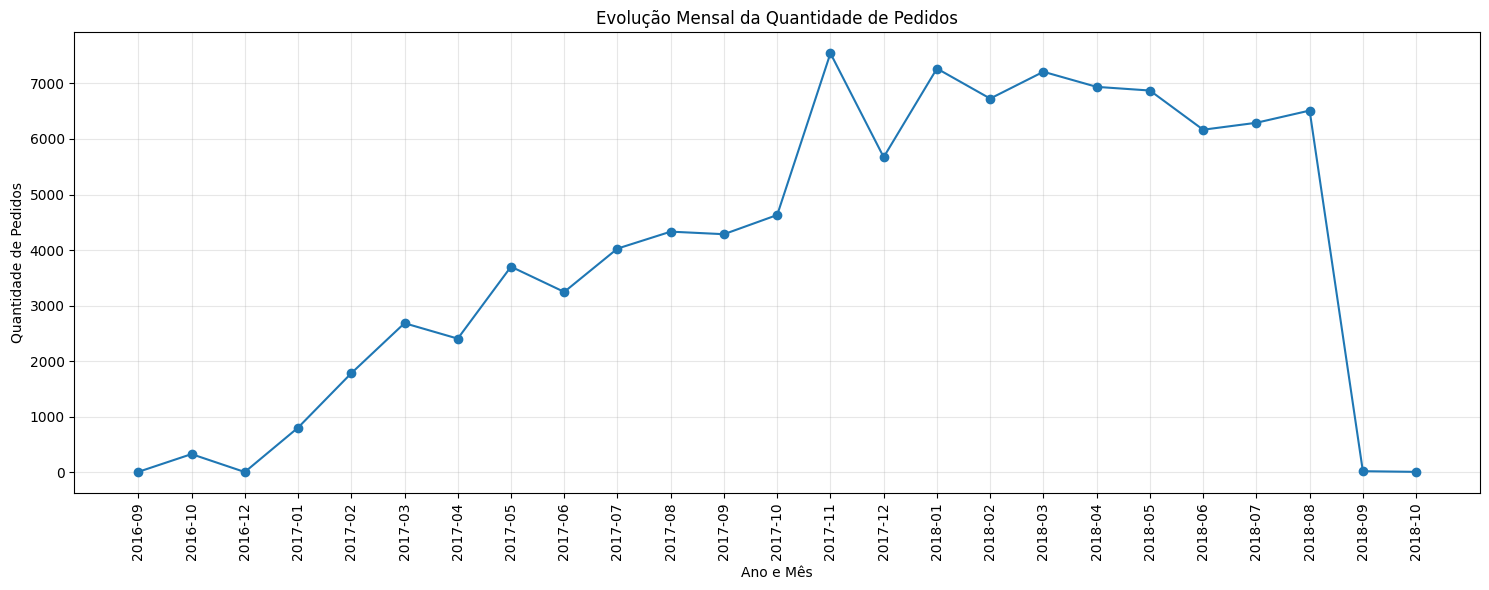

In [ ]:
dados_temporais = pedidos_temporais.toPandas()

plt.figure(figsize=(15, 6))

plt.plot(
    dados_temporais["ano_mes"],
    dados_temporais["quantidade_pedidos"],
    marker="o"
)

plt.title("Evolução Mensal da Quantidade de Pedidos")
plt.xlabel("Ano e Mês")
plt.ylabel("Quantidade de Pedidos")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Verificação do período dos pedidos

Identifica a primeira e a última data de compra e verifica a quantidade de dias com pedidos e o total de pedidos em cada mês.

In [ ]:
# Verificar o período total dos pedidos

orders.select(
    F.min("order_purchase_timestamp").alias("primeira_compra"),
    F.max("order_purchase_timestamp").alias("ultima_compra")
).show(truncate=False)

# Verificar quantidade de datas distintas por mês
pedidos_por_dia = (
    orders
    .withColumn(
        "data_compra",
        F.to_date("order_purchase_timestamp")
    )
    .filter(
        F.col("data_compra").isNotNull()
    )
    .withColumn(
        "ano_mes",
        F.date_format("data_compra", "yyyy-MM")
    )
    .groupBy("ano_mes")
    .agg(
        F.countDistinct("data_compra").alias("dias_com_pedidos"),
        F.count("*").alias("total_pedidos")
    )
    .orderBy("ano_mes")
)

display(pedidos_por_dia)

+-------------------+-------------------+
|primeira_compra    |ultima_compra      |
+-------------------+-------------------+
|2016-09-04 21:15:19|2018-10-17 17:30:18|
+-------------------+-------------------+



DataFrame[ano_mes: string, dias_com_pedidos: bigint, total_pedidos: bigint]

## Exibição dos pedidos por dia

Exibe os resultados da quantidade de dias com pedidos e do total de pedidos por mês para facilitar a conferência dos dados.

In [ ]:
pedidos_por_dia.show(30, truncate=False)

+-------+----------------+-------------+
|ano_mes|dias_com_pedidos|total_pedidos|
+-------+----------------+-------------+
|2016-09|4               |4            |
|2016-10|10              |324          |
|2016-12|1               |1            |
|2017-01|27              |800          |
|2017-02|28              |1780         |
|2017-03|31              |2682         |
|2017-04|30              |2404         |
|2017-05|31              |3700         |
|2017-06|30              |3245         |
|2017-07|31              |4026         |
|2017-08|31              |4331         |
|2017-09|30              |4285         |
|2017-10|31              |4631         |
|2017-11|30              |7544         |
|2017-12|31              |5673         |
|2018-01|31              |7269         |
|2018-02|28              |6728         |
|2018-03|31              |7211         |
|2018-04|30              |6939         |
|2018-05|31              |6873         |
|2018-06|30              |6167         |
|2018-07|31     

## Verificação dos últimos meses da base

Filtra os meses de agosto, setembro e outubro de 2018 para investigar a redução no volume de pedidos no final do período analisado.

In [ ]:
pedidos_por_dia.filter(
    F.col("ano_mes").isin(
        "2018-08",
        "2018-09",
        "2018-10"
    )
).show(truncate=False)

+-------+----------------+-------------+
|ano_mes|dias_com_pedidos|total_pedidos|
+-------+----------------+-------------+
|2018-08|31              |6512         |
|2018-09|11              |16           |
|2018-10|4               |4            |
+-------+----------------+-------------+



## Estatísticas descritivas de preços e fretes

Calcula a média, mediana, valores mínimo e máximo e desvio padrão dos preços e valores de frete dos itens.

In [ ]:
itens = tabelas["olist_order_items_dataset"]

estatisticas = itens.select(
    F.count("*").alias("total_itens"),
    F.mean(F.col("price").cast("double")).alias("preco_medio"),
    F.expr("percentile_approx(CAST(price AS DOUBLE), 0.5)").alias("preco_mediano"),
    F.min(F.col("price").cast("double")).alias("preco_minimo"),
    F.max(F.col("price").cast("double")).alias("preco_maximo"),
    F.stddev(F.col("price").cast("double")).alias("desvio_padrao_preco"),
    F.mean(F.col("freight_value").cast("double")).alias("frete_medio"),
    F.expr("percentile_approx(CAST(freight_value AS DOUBLE), 0.5)").alias("frete_mediano"),
    F.min(F.col("freight_value").cast("double")).alias("frete_minimo"),
    F.max(F.col("freight_value").cast("double")).alias("frete_maximo")
)

estatisticas.show(truncate=False)

+-----------+------------------+-------------+------------+------------+-------------------+-----------------+-------------+------------+------------+
|total_itens|preco_medio       |preco_mediano|preco_minimo|preco_maximo|desvio_padrao_preco|frete_medio      |frete_mediano|frete_minimo|frete_maximo|
+-----------+------------------+-------------+------------+------------+-------------------+-----------------+-------------+------------+------------+
|112650     |120.65373901477311|74.99        |0.85        |6735.0      |183.6339280502597  |19.99031992898562|16.26        |0.0         |409.68      |
+-----------+------------------+-------------+------------+------------+-------------------+-----------------+-------------+------------+------------+



## Distribuição dos preços dos produtos

Gera um histograma para visualizar a frequência dos preços dos produtos e identificar sua concentração e dispersão.

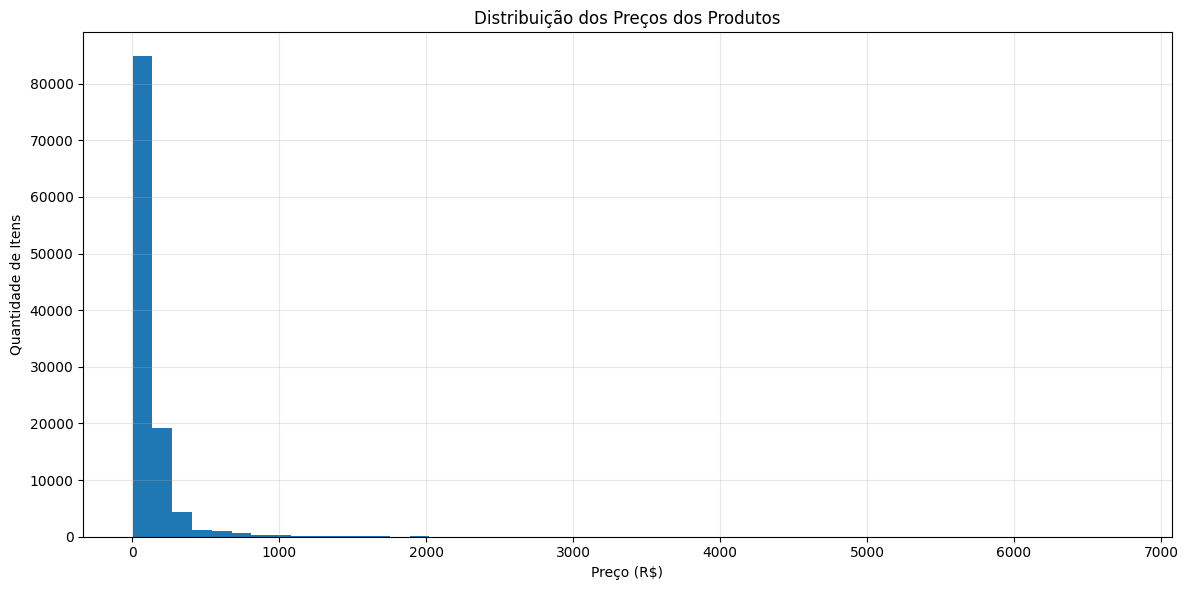

In [ ]:
dados_precos = (
    itens
    .select(F.col("price").cast("double").alias("preco"))
    .toPandas()
)

plt.figure(figsize=(12, 6))

plt.hist(dados_precos["preco"], bins=50)

plt.title("Distribuição dos Preços dos Produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Quantidade de Itens")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Distribuição dos valores de frete

Gera um histograma para visualizar a frequência dos valores de frete e identificar sua concentração e dispersão.

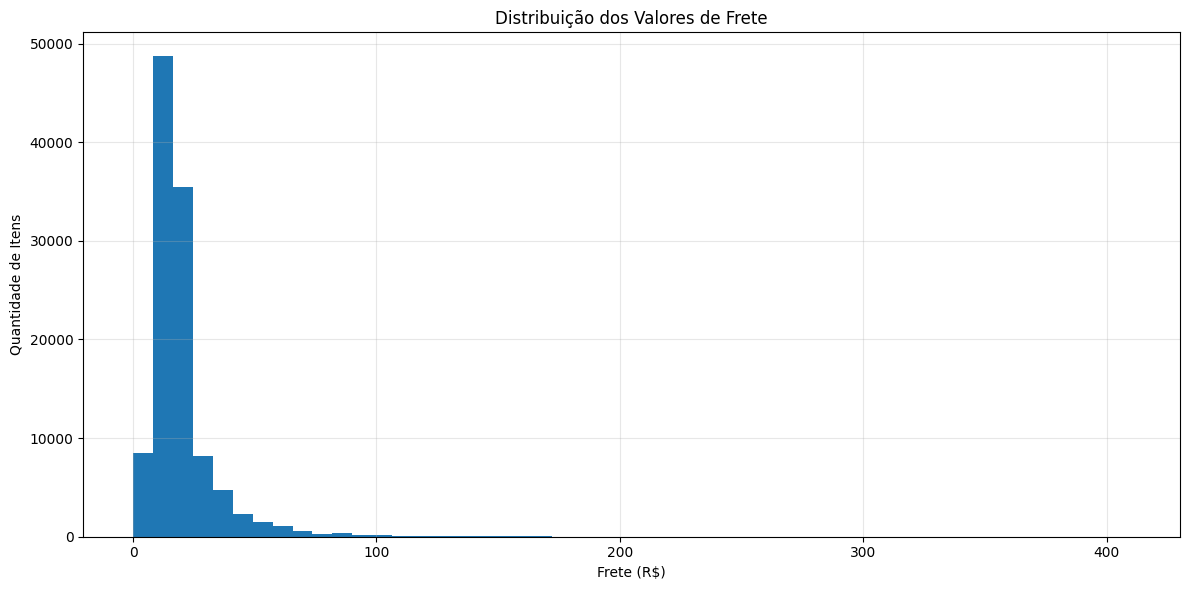

In [ ]:
dados_fretes = (
    itens
    .select(F.col("freight_value").cast("double").alias("frete"))
    .toPandas()
)

plt.figure(figsize=(12, 6))

plt.hist(dados_fretes["frete"], bins=50)

plt.title("Distribuição dos Valores de Frete")
plt.xlabel("Frete (R$)")
plt.ylabel("Quantidade de Itens")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Identificação de possíveis outliers

Calcula os quartis, o intervalo interquartil (IQR) e os limites inferior e superior para identificar possíveis valores atípicos nos preços e fretes.

In [ ]:
# Criando uma versão numérica temporária dos valores
itens_numericos = itens.select(
    F.col("price").cast("double").alias("preco"),
    F.col("freight_value").cast("double").alias("frete")
)

# Analisando preços e fretes
for coluna in ["preco", "frete"]:

    q1, q3 = itens_numericos.approxQuantile(
        coluna, [0.25, 0.75], 0.01
    )

    iqr = q3 - q1

    limite_inferior = q1 - (1.5 * iqr)
    limite_superior = q3 + (1.5 * iqr)

    outliers = itens_numericos.filter(
        (F.col(coluna) < limite_inferior) |
        (F.col(coluna) > limite_superior)
    ).count()

    print(f"\nAnálise: {coluna.upper()}")
    print(f"Q1: R$ {q1:.2f}")
    print(f"Q3: R$ {q3:.2f}")
    print(f"IQR: R$ {iqr:.2f}")
    print(f"Limite inferior: R$ {limite_inferior:.2f}")
    print(f"Limite superior: R$ {limite_superior:.2f}")
    print(f"Quantidade de possíveis outliers: {outliers}")


Análise: PRECO
Q1: R$ 39.89
Q3: R$ 130.00
IQR: R$ 90.11
Limite inferior: R$ -95.27
Limite superior: R$ 265.16
Quantidade de possíveis outliers: 8896

Análise: FRETE
Q1: R$ 12.90
Q3: R$ 20.96
IQR: R$ 8.06
Limite inferior: R$ 0.81
Limite superior: R$ 33.05
Quantidade de possíveis outliers: 12224


## Classificação dos outliers

Conta os valores que estão abaixo e acima dos limites estabelecidos pelo método IQR para preços e fretes.

In [ ]:
for coluna, inferior, superior in [
    ("preco", -95.27, 265.16),
    ("frete", 0.81, 33.05)
]:

    abaixo = itens_numericos.filter(
        F.col(coluna) < inferior
    ).count()

    acima = itens_numericos.filter(
        F.col(coluna) > superior
    ).count()

    print(f"\n{coluna.upper()}")
    print(f"Abaixo do limite inferior: {abaixo}")
    print(f"Acima do limite superior: {acima}")


PRECO
Abaixo do limite inferior: 0
Acima do limite superior: 8896

FRETE
Abaixo do limite inferior: 509
Acima do limite superior: 11715


## Correlação entre preço e frete

Calcula o coeficiente de correlação entre os preços dos produtos e os valores de frete para avaliar a relação entre essas variáveis.

In [ ]:
correlacao = itens_numericos.stat.corr("preco", "frete")

print(f"Correlação entre preço e frete: {correlacao:.4f}")

Correlação entre preço e frete: 0.4142


## Distribuição de clientes únicos por estado

Agrupa os clientes por estado, contabiliza os identificadores únicos e organiza os resultados em ordem decrescente.

In [ ]:
clientes = tabelas["olist_customers_dataset"]

clientes_por_estado = (
    clientes
    .groupBy("customer_state")
    .agg(
        F.countDistinct("customer_unique_id").alias("clientes_unicos")
    )
    .orderBy(F.desc("clientes_unicos"))
)

clientes_por_estado.show(30, truncate=False)

+--------------+---------------+
|customer_state|clientes_unicos|
+--------------+---------------+
|SP            |40302          |
|RJ            |12384          |
|MG            |11259          |
|RS            |5277           |
|PR            |4882           |
|SC            |3534           |
|BA            |3277           |
|DF            |2075           |
|ES            |1964           |
|GO            |1952           |
|PE            |1609           |
|CE            |1313           |
|PA            |949            |
|MT            |876            |
|MA            |726            |
|MS            |694            |
|PB            |519            |
|PI            |482            |
|RN            |474            |
|AL            |401            |
|SE            |342            |
|TO            |273            |
|RO            |240            |
|AM            |143            |
|AC            |77             |
|AP            |67             |
|RR            |45             |
+---------

## Visualização da distribuição de clientes por estado

Gera um gráfico de barras horizontais para comparar a quantidade de clientes únicos entre os estados brasileiros.

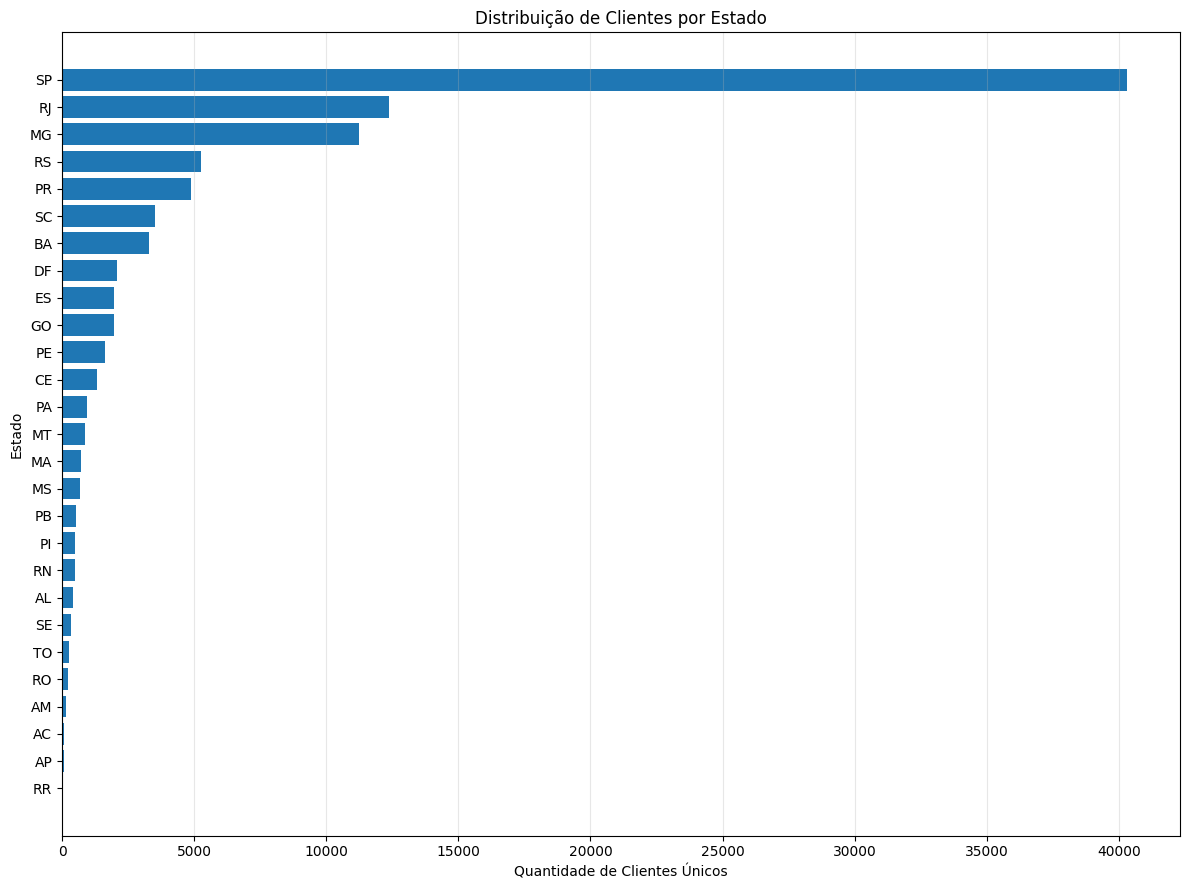

In [ ]:
dados_clientes_estado = clientes_por_estado.toPandas()

plt.figure(figsize=(12, 9))

plt.barh(
    dados_clientes_estado["customer_state"],
    dados_clientes_estado["clientes_unicos"]
)

plt.title("Distribuição de Clientes por Estado")
plt.xlabel("Quantidade de Clientes Únicos")
plt.ylabel("Estado")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Distribuição de pedidos por estado

Relaciona as tabelas de pedidos e clientes por meio do identificador do cliente, agrupa os pedidos por estado e contabiliza os pedidos distintos em cada região.

In [ ]:
pedidos_por_estado = (
    tabelas["olist_orders_dataset"]
    .join(
        tabelas["olist_customers_dataset"].select(
            "customer_id",
            "customer_state"
        ),
        on="customer_id",
        how="inner"
    )
    .groupBy("customer_state")
    .agg(
        F.countDistinct("order_id").alias("quantidade_pedidos")
    )
    .orderBy(F.desc("quantidade_pedidos"))
)

pedidos_por_estado.show(30, truncate=False)

+--------------+------------------+
|customer_state|quantidade_pedidos|
+--------------+------------------+
|SP            |41746             |
|RJ            |12852             |
|MG            |11635             |
|RS            |5466              |
|PR            |5045              |
|SC            |3637              |
|BA            |3380              |
|DF            |2140              |
|ES            |2033              |
|GO            |2020              |
|PE            |1652              |
|CE            |1336              |
|PA            |975               |
|MT            |907               |
|MA            |747               |
|MS            |715               |
|PB            |536               |
|PI            |495               |
|RN            |485               |
|AL            |413               |
|SE            |350               |
|TO            |280               |
|RO            |253               |
|AM            |148               |
|AC            |81          

## Estatísticas do tempo de entrega dos pedidos

Filtra os pedidos entregues com datas válidas, calcula o tempo entre a compra e a entrega em dias e apresenta medidas estatísticas, como média, mediana, valores mínimo e máximo e desvio padrão.

In [ ]:
orders = tabelas["olist_orders_dataset"]

pedidos_entrega = (
    orders
    .filter(
        (F.col("order_status") == "delivered") &
        F.col("order_delivered_customer_date").isNotNull() &
        F.col("order_purchase_timestamp").isNotNull()
    )
    .withColumn(
        "data_compra",
        F.to_timestamp("order_purchase_timestamp")
    )
    .withColumn(
        "data_entrega",
        F.to_timestamp("order_delivered_customer_date")
    )
    .withColumn(
        "dias_entrega",
        F.datediff(
            F.to_date("data_entrega"),
            F.to_date("data_compra")
        )
    )
)

pedidos_entrega.select(
    F.count("*").alias("total_pedidos_entregues"),
    F.round(F.avg("dias_entrega"), 2).alias("media_dias_entrega"),
    F.expr("percentile_approx(dias_entrega, 0.5)").alias("mediana_dias_entrega"),
    F.min("dias_entrega").alias("minimo_dias"),
    F.max("dias_entrega").alias("maximo_dias"),
    F.round(F.stddev("dias_entrega"), 2).alias("desvio_padrao")
).show()

+-----------------------+------------------+--------------------+-----------+-----------+-------------+
|total_pedidos_entregues|media_dias_entrega|mediana_dias_entrega|minimo_dias|maximo_dias|desvio_padrao|
+-----------------------+------------------+--------------------+-----------+-----------+-------------+
|                  96470|              12.5|                  10|          0|        210|         9.56|
+-----------------------+------------------+--------------------+-----------+-----------+-------------+



## Classificação dos pedidos por prazo de entrega

Compara a data real de entrega com a data estimada, classifica os pedidos como atrasados ou entregues no prazo e calcula a quantidade e o percentual de cada situação.

In [ ]:
pedidos_atraso = (
    pedidos_entrega
    .withColumn(
        "data_estimada",
        F.to_date("order_estimated_delivery_date")
    )
    .withColumn(
        "data_entrega_real",
        F.to_date("data_entrega")
    )
    .withColumn(
        "situacao_entrega",
        F.when(
            F.col("data_entrega_real") > F.col("data_estimada"),
            "Atrasado"
        ).otherwise("No prazo")
    )
)

pedidos_atraso.groupBy("situacao_entrega").agg(
    F.count("*").alias("quantidade"),
    F.round(
        F.count("*") * 100 / F.sum(F.count("*")).over(
            Window.partitionBy()
        ), 2
    ).alias("percentual")
).show()

+----------------+----------+----------+
|situacao_entrega|quantidade|percentual|
+----------------+----------+----------+
|        Atrasado|      6534|      6.77|
|        No prazo|     89936|     93.23|
+----------------+----------+----------+



## Visualização da estrutura das avaliações

Exibe o schema e as cinco primeiras linhas da tabela de avaliações para verificar suas colunas, tipos de dados e informações disponíveis.

In [ ]:
reviews = tabelas["olist_order_reviews_dataset"]

reviews.printSchema()

reviews.show(5, truncate=False)

root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: string (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: string (nullable = true)
 |-- review_answer_timestamp: string (nullable = true)

+--------------------------------+--------------------------------+------------+--------------------+----------------------------------------------------------------------------------------------------+--------------------+-----------------------+
|review_id                       |order_id                        |review_score|review_comment_title|review_comment_message                                                                              |review_creation_date|review_answer_timestamp|
+--------------------------------+--------------------------------+------------+--------------------+-----------------------------------------------------------

## Verificação de notas inválidas nas avaliações

Tenta converter as notas das avaliações para valores numéricos, identifica os registros que não podem ser convertidos e exibe a quantidade e alguns exemplos encontrados.

In [ ]:
reviews = tabelas["olist_order_reviews_dataset"]

# Identificar valores que não podem ser convertidos em números
avaliacoes_invalidas = (
    reviews
    .withColumn(
        "review_score_convertido",
        F.expr("try_cast(review_score AS double)")
    )
    .filter(
        F.col("review_score").isNotNull() &
        F.col("review_score_convertido").isNull()
    )
)

print("Quantidade de registros com notas inválidas:")
print(avaliacoes_invalidas.count())

print("\nExemplos encontrados:")
avaliacoes_invalidas.select(
    "review_id",
    "order_id",
    "review_score",
    "review_creation_date",
    "review_answer_timestamp"
).show(10, truncate=False)

Quantidade de registros com notas inválidas:
16

Exemplos encontrados:
+-------------------------------------------------------------------------------------------+-------------------------------------+----------------------+--------------------+-----------------------+
|review_id                                                                                  |order_id                             |review_score          |review_creation_date|review_answer_timestamp|
+-------------------------------------------------------------------------------------------+-------------------------------------+----------------------+--------------------+-----------------------+
|Ficou a dúvida se o cartucho é original."                                                  |2018-06-29 00:00:00                  |2018-06-30 14:05:00   |NULL                |NULL                   |
|Assim                                                                                      | solicito esclarecimentos."         

## Relação entre prazo de entrega e avaliações dos clientes

Converte as notas para valores numéricos, mantém avaliações válidas entre 1 e 5, calcula a nota média por pedido e cruza essas informações com a situação da entrega para comparar a média e a mediana das avaliações.

In [ ]:
# Converter as notas e manter somente valores válidos
avaliacoes_por_pedido = (
    reviews
    .withColumn(
        "review_score_num",
        F.expr("try_cast(review_score AS double)")
    )
    .filter(
        F.col("review_score_num").between(1, 5)
    )
    .groupBy("order_id")
    .agg(
        F.avg("review_score_num").alias("nota_media")
    )
)

# Cruzar avaliações com a situação da entrega
entrega_avaliacao = (
    pedidos_atraso
    .join(avaliacoes_por_pedido, on="order_id", how="inner")
)

# Comparar as avaliações
resumo_avaliacoes = (
    entrega_avaliacao
    .groupBy("situacao_entrega")
    .agg(
        F.count("*").alias("quantidade_pedidos"),
        F.round(F.avg("nota_media"), 2).alias("media_avaliacao"),
        F.round(
            F.expr("percentile_approx(nota_media, 0.5)"), 2
        ).alias("mediana_avaliacao")
    )
    .orderBy("situacao_entrega")
)

resumo_avaliacoes.show()

+----------------+------------------+---------------+-----------------+
|situacao_entrega|quantidade_pedidos|media_avaliacao|mediana_avaliacao|
+----------------+------------------+---------------+-----------------+
|        Atrasado|              6381|           2.27|              1.0|
|        No prazo|             89442|           4.29|              5.0|
+----------------+------------------+---------------+-----------------+



## Análise de itens, preços e fretes por pedido

Agrupa os itens por pedido e calcula a quantidade de produtos, o valor total dos produtos e o valor total do frete, exibindo alguns resultados para conferência.

In [ ]:
# Analisar quantidade de produtos, preço e frete por pedido

itens = tabelas["olist_order_items_dataset"]

analise_pedidos = (
    itens
    .groupBy("order_id")
    .agg(
        F.count("*").alias("quantidade_itens"),
        F.round(
            F.sum(F.col("price").cast("double")), 2
        ).alias("valor_total_produtos"),
        F.round(
            F.sum(F.col("freight_value").cast("double")), 2
        ).alias("valor_total_frete")
    )
)

# Exibir os primeiros resultados
analise_pedidos.show(10, truncate=False)

+--------------------------------+----------------+--------------------+-----------------+
|order_id                        |quantidade_itens|valor_total_produtos|valor_total_frete|
+--------------------------------+----------------+--------------------+-----------------+
|014405982914c2cde2796ddcf0b8703d|2               |49.23               |29.2             |
|019886de8f385a39b75bedbb726fd4ef|1               |159.9               |28.5             |
|01a6ad782455876aa89081449d49c452|1               |34.99               |15.1             |
|01d907b3e209269e120a365fc2b97524|1               |151.99              |17.77            |
|028dc52e12ddda803ec1e35eb0b7b0d9|1               |49.99               |11.73            |
|036dd381dfb3ec75e0a63e14828cc871|1               |55.0                |14.14            |
|03ebfa9712b7dbc7031291856263b314|1               |46.9                |8.88             |
|0420da8d50a3784011290a782f25a8a8|1               |59.9                |14.73            |

## Correlação entre quantidade de itens, preços e fretes

Calcula os coeficientes de correlação entre a quantidade de itens, o valor total dos produtos e o valor total do frete por pedido, permitindo avaliar a intensidade e a direção das relações entre essas variáveis.

In [ ]:
# Calcular correlações entre quantidade, preço e frete

correlacao_quantidade_preco = analise_pedidos.stat.corr(
    "quantidade_itens",
    "valor_total_produtos"
)

correlacao_quantidade_frete = analise_pedidos.stat.corr(
    "quantidade_itens",
    "valor_total_frete"
)

correlacao_preco_frete = analise_pedidos.stat.corr(
    "valor_total_produtos",
    "valor_total_frete"
)

print("CORRELAÇÕES ENTRE AS VARIÁVEIS")
print("-" * 45)

print(f"Quantidade de itens x Valor dos produtos: {correlacao_quantidade_preco:.4f}")
print(f"Quantidade de itens x Valor do frete: {correlacao_quantidade_frete:.4f}")
print(f"Valor dos produtos x Valor do frete: {correlacao_preco_frete:.4f}")

CORRELAÇÕES ENTRE AS VARIÁVEIS
---------------------------------------------
Quantidade de itens x Valor dos produtos: 0.1531
Quantidade de itens x Valor do frete: 0.4369
Valor dos produtos x Valor do frete: 0.4128


## Matriz de correlação entre itens, produtos e frete

Calcula a matriz de correlação entre a quantidade de itens, o valor total dos produtos e o valor total do frete por pedido e apresenta os resultados em um mapa de calor para facilitar a identificação das relações entre as variáveis.

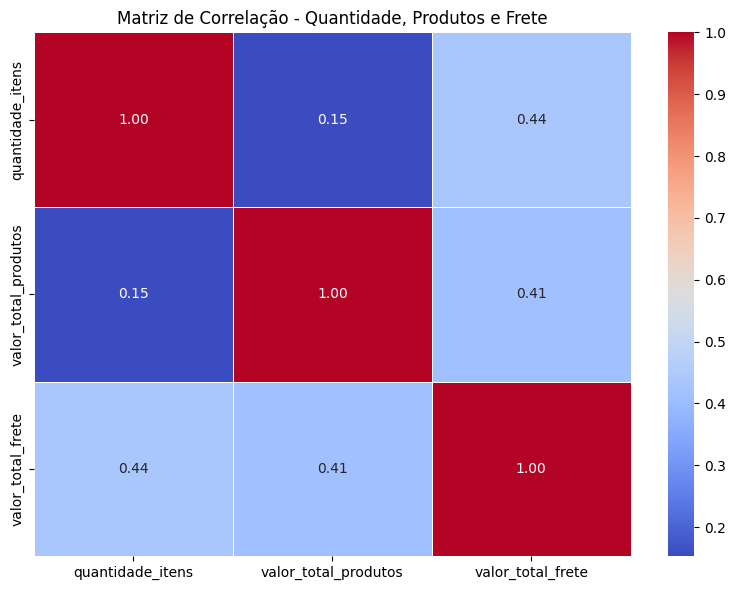

In [ ]:
# Criar matriz de correlação
matriz_correlacao = analise_pedidos.select(
    "quantidade_itens",
    "valor_total_produtos",
    "valor_total_frete"
).toPandas().corr()

# Exibir mapa de calor
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de Correlação - Quantidade, Produtos e Frete")
plt.tight_layout()
plt.show()

## Resumo estrutural das tabelas

Percorre todas as tabelas carregadas, contabiliza a quantidade de linhas e colunas de cada uma e apresenta um resumo da estrutura das bases de dados.

In [ ]:
# Resumo estrutural das tabelas do projeto

for nome_tabela, dataframe in tabelas.items():

    quantidade_linhas = dataframe.count()
    quantidade_colunas = len(dataframe.columns)

    print(
        f"Tabela: {nome_tabela} | "
        f"Linhas: {quantidade_linhas} | "
        f"Colunas: {quantidade_colunas}"
    )

Tabela: olist_customers_dataset | Linhas: 99441 | Colunas: 5
Tabela: olist_geolocation_dataset | Linhas: 1000163 | Colunas: 5
Tabela: olist_order_items_dataset | Linhas: 112650 | Colunas: 7
Tabela: olist_order_payments_dataset | Linhas: 103886 | Colunas: 5
Tabela: olist_order_reviews_dataset | Linhas: 99249 | Colunas: 7
Tabela: olist_orders_dataset | Linhas: 99441 | Colunas: 8
Tabela: olist_products_dataset | Linhas: 32951 | Colunas: 9
Tabela: olist_sellers_dataset | Linhas: 3095 | Colunas: 4
Tabela: product_category_name_translation | Linhas: 71 | Colunas: 2


## Verificação de valores ausentes nas tabelas

Percorre todas as tabelas e verifica, em cada coluna, a presença de valores nulos ou campos vazios, apresentando a quantidade e o percentual de registros ausentes.

In [ ]:
# Verificar valores ausentes em todas as tabelas

for nome_tabela, dataframe in tabelas.items():

    total = dataframe.count()

    print("\n" + "=" * 70)
    print(f"TABELA: {nome_tabela}")
    print("=" * 70)

    for coluna in dataframe.columns:

        ausentes = dataframe.filter(
            F.col(coluna).isNull() |
            (F.trim(F.col(coluna)) == "")
        ).count()

        if ausentes > 0:
            percentual = round((ausentes / total) * 100, 2)

            print(
                f"{coluna}: {ausentes} valores ausentes "
                f"({percentual}%)"
            )


TABELA: olist_customers_dataset

TABELA: olist_geolocation_dataset

TABELA: olist_order_items_dataset

TABELA: olist_order_payments_dataset

TABELA: olist_order_reviews_dataset
order_id: 9 valores ausentes (0.01%)
review_score: 10 valores ausentes (0.01%)
review_comment_title: 87679 valores ausentes (88.34%)
review_comment_message: 58281 valores ausentes (58.72%)
review_creation_date: 44 valores ausentes (0.04%)
review_answer_timestamp: 46 valores ausentes (0.05%)

TABELA: olist_orders_dataset
order_approved_at: 160 valores ausentes (0.16%)
order_delivered_carrier_date: 1783 valores ausentes (1.79%)
order_delivered_customer_date: 2965 valores ausentes (2.98%)

TABELA: olist_products_dataset
product_category_name: 610 valores ausentes (1.85%)
product_name_lenght: 610 valores ausentes (1.85%)
product_description_lenght: 610 valores ausentes (1.85%)
product_photos_qty: 610 valores ausentes (1.85%)
product_weight_g: 2 valores ausentes (0.01%)
product_length_cm: 2 valores ausentes (0.01%)


## Verificação de registros duplicados

Percorre todas as tabelas, identifica registros totalmente duplicados, calcula sua quantidade e percentual em relação ao total de registros de cada tabela.

In [ ]:
# Verificar registros totalmente duplicados em cada tabela

for nome_tabela, dataframe in tabelas.items():

    total_registros = dataframe.count()

    registros_unicos = dataframe.dropDuplicates().count()

    duplicados = total_registros - registros_unicos

    percentual = round(
        (duplicados / total_registros) * 100, 2
    )

    print(
        f"Tabela: {nome_tabela} | "
        f"Duplicados: {duplicados} | "
        f"Percentual: {percentual}%"
    )

Tabela: olist_customers_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_geolocation_dataset | Duplicados: 261831 | Percentual: 26.18%
Tabela: olist_order_items_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_order_payments_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_order_reviews_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_orders_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_products_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: olist_sellers_dataset | Duplicados: 0 | Percentual: 0.0%
Tabela: product_category_name_translation | Duplicados: 0 | Percentual: 0.0%


## Identificação de registros duplicados na geolocalização

Agrupa os registros da tabela de geolocalização considerando todas as colunas, identifica as combinações repetidas e apresenta os exemplos com maior quantidade de ocorrências.

In [ ]:
# Identificar registros totalmente duplicados na geolocalização

geolocalizacao = tabelas["olist_geolocation_dataset"]

duplicados_geo = (
    geolocalizacao
    .groupBy(geolocalizacao.columns)
    .agg(
        F.count("*").alias("quantidade_repeticoes")
    )
    .filter(F.col("quantidade_repeticoes") > 1)
    .orderBy(F.desc("quantidade_repeticoes"))
)

duplicados_geo.show(10, truncate=False)

## Verificação de duplicidade nas principais chaves

Verifica a unicidade dos identificadores principais das tabelas de clientes, pedidos, produtos, vendedores e avaliações, comparando o total de registros com a quantidade de identificadores distintos.

In [ ]:
# Verificar duplicidade nas principais chaves

chaves = {
    "customers": ("olist_customers_dataset", "customer_id"),
    "orders": ("olist_orders_dataset", "order_id"),
    "products": ("olist_products_dataset", "product_id"),
    "sellers": ("olist_sellers_dataset", "seller_id"),
    "reviews": ("olist_order_reviews_dataset", "review_id")
}

for nome, (tabela, coluna) in chaves.items():

    df = tabelas[tabela]

    total = df.count()
    distintos = df.select(coluna).distinct().count()

    repetidos = total - distintos

    print(
        f"Tabela: {nome} | "
        f"Total: {total} | "
        f"Identificadores distintos: {distintos} | "
        f"Repetições: {repetidos}"
    )

## Identificação de avaliações com identificadores repetidos

Agrupa os registros da tabela de avaliações pelo identificador da avaliação, contabiliza suas ocorrências e exibe os identificadores que aparecem mais de uma vez.

In [ ]:
reviews = tabelas["olist_order_reviews_dataset"]

reviews_repetidas = (
    reviews
    .groupBy("review_id")
    .agg(
        F.count("*").alias("quantidade")
    )
    .filter(F.col("quantidade") > 1)
    .orderBy(F.desc("quantidade"))
)

reviews_repetidas.show(10, truncate=False)

## Análise detalhada das avaliações repetidas

Seleciona os identificadores de avaliações repetidos, recupera todos os registros correspondentes na tabela original e exibe os resultados para investigar possíveis diferenças entre as ocorrências.

In [ ]:
ids_repetidos = (
    reviews_repetidas
    .select("review_id")
)

reviews.join(
    ids_repetidos,
    on="review_id",
    how="inner"
).orderBy("review_id").show(20, truncate=False)

## Encerramento da sessão Spark

Encerra a sessão do Spark e libera os recursos utilizados durante o processamento dos dados.

In [ ]:
spark.stop()

print("Sessão Spark encerrada com sucesso!")

## Conclusão geral da análise exploratória

A análise exploratória do conjunto de dados da Olist permitiu conhecer melhor as características das operações de comércio eletrônico, considerando informações sobre pedidos, clientes, produtos, vendedores, pagamentos, entregas e avaliações.

As análises identificaram diferenças na distribuição dos pedidos entre os status, concentração de produtos em determinadas categorias e variações no volume de compras ao longo do tempo.

Na análise financeira, foram investigadas as distribuições dos preços dos produtos e dos valores de frete, incluindo medidas estatísticas, possíveis valores atípicos e correlações entre variáveis.

A análise geográfica demonstrou a distribuição dos clientes e pedidos entre os estados brasileiros. Também foram avaliados os prazos de entrega, identificando que 93,23% dos pedidos analisados foram entregues no prazo e 6,77% apresentaram atraso.

O cruzamento entre avaliações e informações de entrega permitiu investigar a relação entre a experiência de entrega e a percepção dos clientes. A análise da tabela de avaliações também identificou registros múltiplos, valores ausentes e particularidades nos identificadores, que deverão ser considerados em etapas posteriores.

Conclui-se que a análise exploratória foi fundamental para compreender os dados, identificar padrões e levantar pontos de atenção que orientarão as próximas etapas do projeto, especialmente o tratamento e a preparação dos dados para análises posteriores.